# 매출 트렌드 & 상품 분석

In [26]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os

conn = sqlite3.connect('../ecommerce.db')
os.makedirs('../output', exist_ok=True)

def query(sql):
    return pd.read_sql(sql, conn)

# 분석기간 정의
START_DATE = '2017-01-01'
END_DATE = '2018-08-31'

1. 월별 매출 트렌드 & 성장률

In [6]:
monthly_revenue = query(f"""
    --- CTE: 임시 테이블, 월별 매출 합계
    WITH monthly AS (
        SELECT 
            strftime('%Y-%m', o.order_purchase_timestamp) AS month,
            ROUND(SUM(p.payment_value), 2) AS revenue
        FROM orders o
        JOIN payments p USING (order_id)
        WHERE o.order_status = 'delivered' AND o.order_purchase_timestamp BETWEEN '{START_DATE}' AND '{END_DATE}'
        GROUP BY month
    )
    SELECT
        month,
        revenue,
        -- 윈도우 함수 LAG: 이전 행의 값 가져오기
        -- OVER (ORDER BY month): month 순서대로 정렬했을 때
        LAG(revenue) OVER (ORDER BY month) AS prev_revenue,
        ROUND(
            (revenue - LAG(revenue) OVER (ORDER BY month))
            / LAG(revenue) OVER (ORDER BY month) * 100
        , 1)                                                 AS mom_growth_pct
        -- MoM: Month over Month 성장률 = (이번달 - 저번달) / 저번달 * 100
    FROM monthly
    ORDER BY month
""")

display(monthly_revenue)

,month,revenue,prev_revenue,mom_growth_pct
0,2017-01,127545.67,NaN,NaN
1,2017-02,271298.65,127545.67,112.7
2,2017-03,414369.39,271298.65,52.7
3,2017-04,390952.18,414369.39,-5.7
4,2017-05,567066.73,390952.18,45.0
5,2017-06,490225.60,567066.73,-13.6
6,2017-07,566403.93,490225.60,15.5
7,2017-08,646000.61,566403.93,14.1
8,2017-09,701169.99,646000.61,8.5
9,2017-10,751140.27,701169.99,7.1


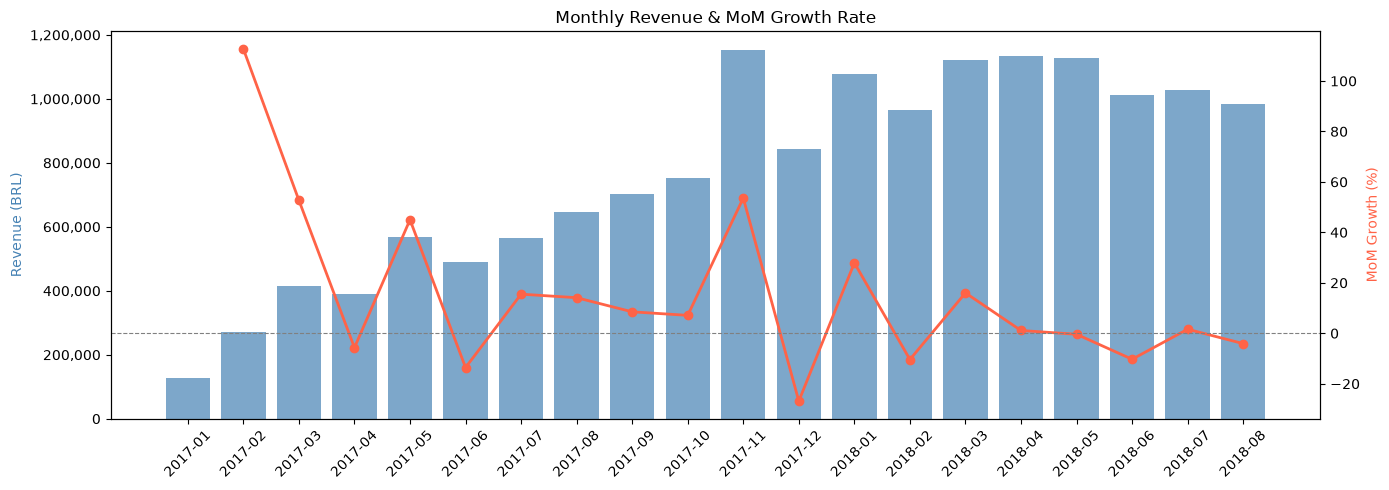

In [5]:
fig, ax1 = plt.subplots(figsize=(14,5))

# 막대 그래프(매출)
ax1.bar(monthly_revenue['month'], monthly_revenue['revenue'],
        color='steelblue', alpha=0.7, label='Revenue')
ax1.set_ylabel('Revenue (BRL)', color='steelblue')
ax1.tick_params(axis='x', rotation=45)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}')) # y축 숫자에 천 단위 콤마 붙이기

# 꺾은선 그래프(성장률)
# twinx(): x축은 공유하고 y축만 오른쪽에 새로 만들기
ax2 = ax1.twinx()
ax2.plot(monthly_revenue['month'], monthly_revenue['mom_growth_pct'],
         color='tomato', marker='o', linewidth=2, label='MoM Growth %')
ax2.axhline(0, color='gray', linewidth=0.8, linestyle='--')
ax2.set_ylabel('MoM Growth (%)', color='tomato')

plt.title('Monthly Revenue & MoM Growth Rate')
fig.tight_layout()
plt.savefig('../output/monthly_revenue.png', dpi=150)
plt.show()

- 성장기   (2017-01 ~ 2017-11) : 월평균 +27% 성장, 블랙프라이데이로 정점
- 조정기   (2017-11 ~ 2018-02) : 블랙프라이데이 반동으로 -26.9% 급락 후 회복
- 안정기   (2018-03 ~ 2018-08) : 월 100만 BRL 내외로 안정화, 성장률 한 자릿수

2. 카테고리별 매출 순위

,category,order_count,revenue,avg_order_value
0,bed_bath_table,9267,1690422.57,145.20
1,health_beauty,8610,1615989.35,166.31
2,computers_accessories,6518,1548510.75,196.44
3,watches_gifts,5491,1384568.74,228.44
4,furniture_decor,6258,1383767.32,163.10
5,sports_leisure,7513,1346956.17,154.54
6,housewares,5734,1067051.45,149.03
7,auto,3802,832394.40,194.67
8,garden_tools,3443,809149.74,181.46
9,cool_stuff,3552,743404.14,190.62


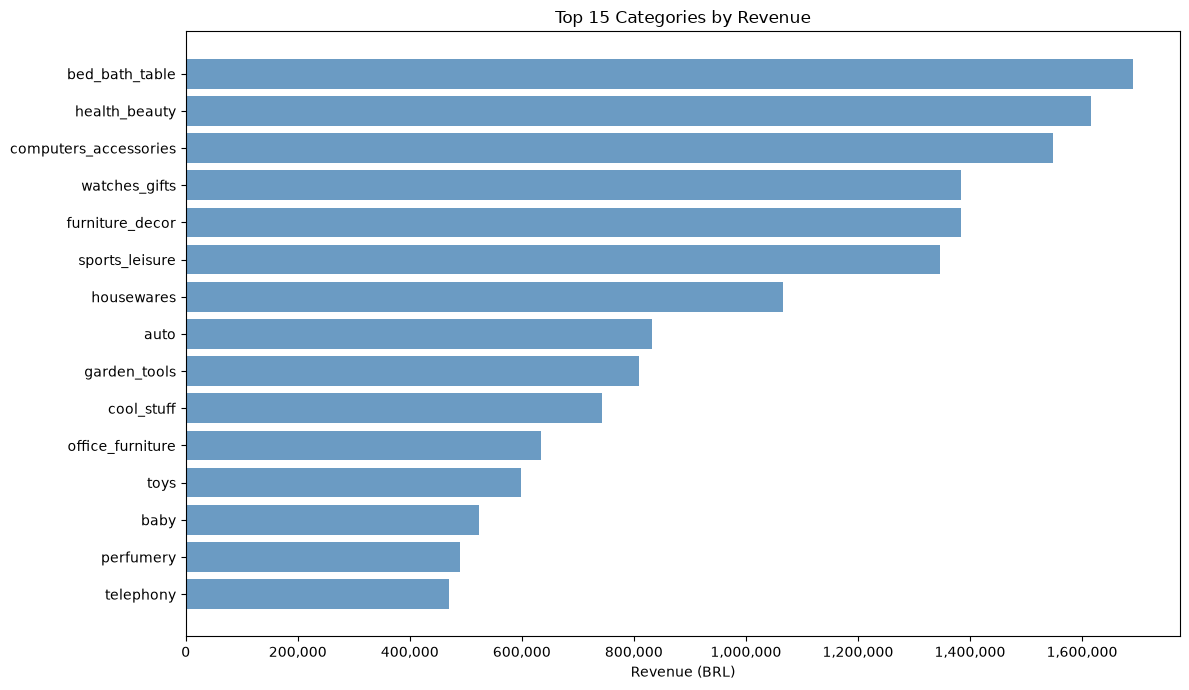

In [13]:
category_revenue = query(f"""
    SELECT
        --- COALESCE: 왼쪽부터 보면서 NULL이 아닌 첫 번째 값 반환
        COALESCE(t.product_category_name_english, p.product_category_name, 'Unknown') AS category,
        COUNT(DISTINCT o.order_id)                     AS order_count,
        ROUND(SUM(pay.payment_value), 2)               AS revenue,
        ROUND(AVG(pay.payment_value), 2)               AS avg_order_value
    FROM orders o
    JOIN order_items oi USING (order_id)
    JOIN products p USING (product_id)
    JOIN payments pay USING (order_id)
    LEFT JOIN category_translation t
           ON p.product_category_name = t.product_category_name
    WHERE o.order_status = 'delivered' AND o.order_purchase_timestamp BETWEEN '{START_DATE}' AND '{END_DATE}'
    GROUP BY category
    ORDER BY revenue DESC
    LIMIT 15
""")

display(category_revenue)

# 시각화
fig, ax = plt.subplots(figsize=(12,7))
bars = ax.barh(category_revenue['category'][::-1], # [::-1] : 순서 뒤집기, barh는 아래에서 위로 쌓으므로 1위가 맨 위로 가도록 함
               category_revenue['revenue'][::-1],
               color='steelblue', alpha=0.8)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.set_xlabel('Revenue (BRL)')
ax.set_title('Top 15 Categories by Revenue')
plt.tight_layout()
plt.savefig('../output/category_revenue.png', dpi=150)
plt.show()

- bed_bath_table      : 매출 1위,  AOV 145  → 주문량으로 먹는 카테고리
- computers_accessories: 매출 3위, AOV 196  → 객단가가 높은 카테고리
- office_furniture    : 매출 11위, AOV 363  → 주문은 적지만 건당 금액이 압도적
- watches_gifts       : 매출 4위,  AOV 228  → 물량 + 객단가 모두 균형

3. AOV(평균 주문 금액) 월별 추이
- AOV: Average Order Value

In [16]:
aov_trend = query(f"""
    SELECT
        strftime('%Y-%m', o.order_purchase_timestamp) AS month,
        COUNT(DISTINCT o.order_id)       AS order_count,
        ROUND(SUM(p.payment_value), 2)   AS revenue,
        ROUND(AVG(p.payment_value), 2)   AS aov
    FROM orders o
    JOIN payments p USING (order_id)
    WHERE o.order_status = 'delivered' AND o.order_purchase_timestamp BETWEEN '{START_DATE}' AND '{END_DATE}'
    GROUP BY month
    ORDER BY month
""")

display(aov_trend)

,month,order_count,revenue,aov
0,2017-01,750,127545.67,159.63
1,2017-02,1653,271298.65,155.12
2,2017-03,2546,414369.39,153.47
3,2017-04,2303,390952.18,160.49
4,2017-05,3546,567066.73,149.74
5,2017-06,3135,490225.60,147.53
6,2017-07,3872,566403.93,136.58
7,2017-08,4193,646000.61,147.05
8,2017-09,4150,701169.99,160.41
9,2017-10,4478,751140.27,159.89


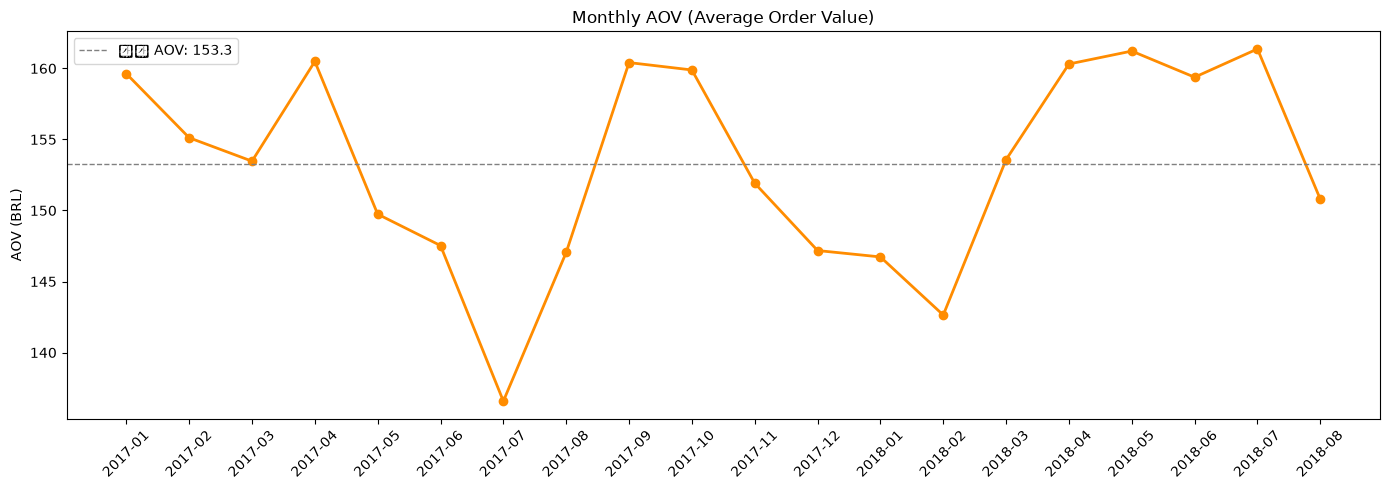

In [27]:
fig, ax = plt.subplots(figsize=(14,5))
ax.plot(aov_trend['month'], aov_trend['aov'],
        marker='o', color='darkorange', linewidth=2)
ax.axhline(aov_trend['aov'].mean(), color='gray',
           linestyle='--', linewidth=1, label=f"평균 AOV: {aov_trend['aov'].mean():.1f}")
ax.set_title('Monthly AOV (Average Order Value)')
ax.set_ylabel('AOV (BRL)')
ax.tick_params(axis='x', rotation=45)
ax.legend()
plt.tight_layout()
plt.savefig('../output/aov_trend.png', dpi=150)
plt.show()

- 최저: 2017-07  136.6 BRL  ← 여름 세일 시즌, 저가 상품 구매 집중
- 최고: 2017-04  160.5 BRL
- 평균: 153.3 BRL

4. 파레토 분석(상위 20% 카테고리가 매출의 몇 %?)

In [33]:
pareto = query(f"""
    --- cat_rev: 카테고리별 매출 집계
    WITH cat_rev AS (
        SELECT
            COALESCE(t.product_category_name_english, p.product_category_name, 'Unknown') AS category,
            ROUND(SUM(pay.payment_value), 2) AS revenue
        FROM orders o
        JOIN order_items oi USING (order_id)
        JOIN products     p USING (product_id)
        JOIN payments   pay USING (order_id)
        LEFT JOIN category_translation t
               ON p.product_category_name = t.product_category_name
        WHERE o.order_status = 'delivered' AND o.order_purchase_timestamp BETWEEN '{START_DATE}' AND '{END_DATE}'
        GROUP BY category
    ),
    --- ranked: 비율 & 누적합 계산
    ranked AS (
        SELECT
            category,
            revenue,
            ROUND(revenue * 100.0 / SUM(revenue) OVER (), 2) AS pct,
            --- SUM(revenue) OVER (): 전체 행 대상, 모든 카테고리 매출 총합
            --- OVER (ORDER BY revenue DESC): OVER 안에 ORDER BY -> 위에서부터 현재 행까지 누적
            ROUND(SUM(revenue) OVER (ORDER BY revenue DESC) * 100.0 / SUM(revenue) OVER (), 2) AS cumulative_pct
        FROM cat_rev
        ORDER BY revenue DESC
    )
    SELECT
        ROW_NUMBER() OVER (ORDER BY revenue DESC) AS rank,
        category,
        revenue,
        pct,
        cumulative_pct
    FROM ranked
""")

display(pareto.head(10))

,rank,category,revenue,pct,cumulative_pct
0,1,bed_bath_table,1690422.57,8.57,8.57
1,2,health_beauty,1615989.35,8.20,16.77
2,3,computers_accessories,1548510.75,7.85,24.63
3,4,watches_gifts,1384568.74,7.02,31.65
4,5,furniture_decor,1383767.32,7.02,38.67
5,6,sports_leisure,1346956.17,6.83,45.50
6,7,housewares,1067051.45,5.41,50.91
7,8,auto,832394.40,4.22,55.14
8,9,garden_tools,809149.74,4.10,59.24
9,10,cool_stuff,743404.14,3.77,63.01


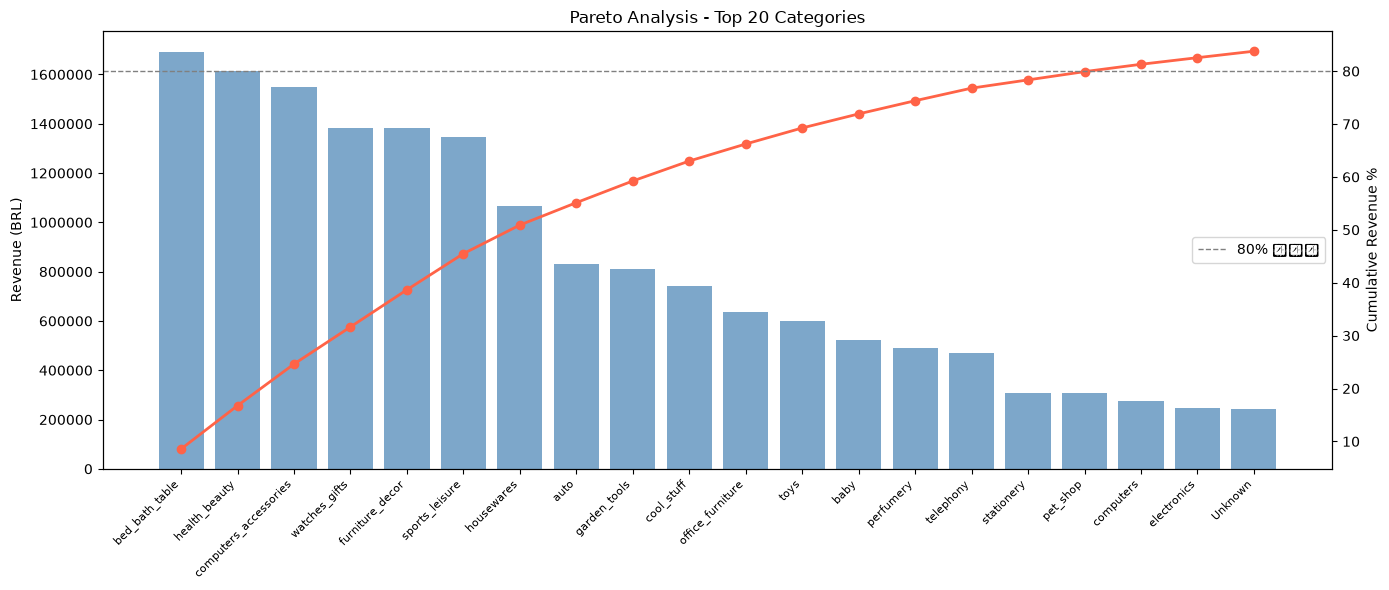

In [34]:
fig, ax1 = plt.subplots(figsize=(14,6))
top_n = pareto.head(20)

ax1.bar(range(len(top_n)), top_n['revenue'], color='steelblue', alpha=0.7)
ax1.set_xticks(range(len(top_n)))
ax1.set_xticklabels(top_n['category'], rotation=45, ha='right', fontsize=8)
ax1.set_ylabel('Revenue (BRL)')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}'))

ax2 = ax1.twinx()
ax2.plot(range(len(top_n)), top_n['cumulative_pct'],
         color='tomato', marker='o', linewidth=2)
ax2.axhline(80, color='gray', linestyle='--', linewidth=1, label='80% 기준선') # y=80 위치에 수평선 긋기
ax2.set_ylabel('Cumulative Revenue %')
ax2.legend(loc='center right')

plt.title('Pareto Analysis - Top 20 Categories')
fig.tight_layout()
plt.savefig('../output/pareto.png', dpi=150)
plt.show()

In [32]:
# 80% 달성에 몇 개 카테고리가 필요한지 확인
threshold = pareto[pareto['cumulative_pct'] <= 80]
print(f"상위 {len(threshold)}개 카테고리가 전체 매출의 80%를 차지합니다.")
print(f"전체 카테고리 수: {len(pareto)}개")
print(f"-> 상위 {len(threshold)/len(pareto)*100:.1f}%의 카테고리가 매출의 80% 기여")

상위 17개 카테고리가 전체 매출의 80%를 차지합니다.
전체 카테고리 수: 74개
-> 상위 23.0%의 카테고리가 매출의 80% 기여


=> 상위 17개 카테고리 (전체 74개의 23%) → 매출의 80% 기여
→ 교과서적인 파레토 법칙 (20:80) 과 매우 근접